# 26 基于 Apriori 算法的商品关联规则挖掘

> **模块**：关联规则 ｜ **数据**：`Online_Retail.xlsx` ｜ **依赖**：numpy、pandas、matplotlib、apyori

## 1. 问题背景

本实验利用某公开线上商品交易数据，通过Apriori算法挖掘商品交易之间的关联规则。

本实验使用的数据来自于Kaggle网站提供的公开数据集，其中包含了2010年12月1日至2011年12月12日期间在英国注册的商店在线零售之间发生的所有交易。具体字段说明如下：

- **InvoiceNo**: 发票号。名义变量，每个交易唯一分配的一个6位整数。如果代码以字母 'c' 开头，则表示该交易为取消。
- **StockCode**: 商品（项目）代码。名义变量，每个不同商品唯一分配的一个5位整数。
- **Description**: 商品（项目）名称。名义变量。
- **Quantity**: 每笔交易中每个商品（项目）的数量。数值型。
- **InvoiceDate**: 发票日期和时间。数值型，每笔交易生成的日期和时间。
- **UnitPrice**: 单价。数值型，商品每单位的价格（英镑）。
- **CustomerID**: 客户编号。名义变量，每个客户唯一分配的一个5位整数。
- **Country**: 国家名称。名义变量，客户所在国家的名称。

本实验首先对数据进行预处理和可视化分析，以查看交易的基本情况；然后将数据转换成“购物篮”数据，利用Apriori算法挖掘商品交易之间的关联规则。


## 2. 学习目标

- 学习建立 Apriori 关联规则模型，生成规则。
- 学习将结构化数据转化为“购物篮”数据。


## 3. 环境与数据

- Jupyter 开发环境。
- Python 3.10。


## 4. 方法与实现

### 4.1 数据准备

#### 4.1.1 导入常用数据分析工具包，并导入数据


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
dataset = pd.read_excel('../data/Online_Retail.xlsx')
dataset.head()

#### 4.1.2 查看数据概况

In [ ]:
# 查看数据概况
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


从运行结果中可以看出，该数据的样本数量为541909，其中Description和customerId列中存在缺失值。

### 4.2 数据预处理和可视化分析

#### 4.2.1 字段预处理

根据单价'UnitPrice'和数量'Quantity'两个变量，计算得到交易的总金额。将交易日期'InvoiceDate'拆分成交易年份'InvoiceYear'和交易月份'InvoiceMonth'。

In [ ]:
dataset['TotalAmount'] = dataset['Quantity'] * dataset['UnitPrice']
dataset['InvoiceYear'] = dataset['InvoiceDate'].dt.year
dataset['InvoiceMonth'] = dataset['InvoiceDate'].dt.month
dataset['InvoiceYearMonth'] = dataset['InvoiceYear'].map(str) + "-" + dataset['InvoiceMonth'].map(str)
dataset.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount,InvoiceYear,InvoiceMonth,InvoiceYearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,12,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,12,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,2010-12


#### 4.2.2 查看产品销量排行

In [ ]:
gp_stockcode = dataset.groupby('Description')
gp_stockcode_frq_quantitiy = gp_stockcode['Quantity'].agg(np.sum).sort_values(ascending=False)
gp_stockcode_frq_quantitiy.head(20)

C:\Users\yohoten\AppData\Local\Temp\ipykernel_68432\4103908213.py:2: FutureWarning: The provided callable <function sum at 0x0000021E873E5DA0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  gp_stockcode_frq_quantitiy = gp_stockcode['Quantity'].agg(np.sum).sort_values(ascending=False)


Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53847
JUMBO BAG RED RETROSPOT               47363
ASSORTED COLOUR BIRD ORNAMENT         36381
POPCORN HOLDER                        36334
PACK OF 72 RETROSPOT CAKE CASES       36039
WHITE HANGING HEART T-LIGHT HOLDER    35317
RABBIT NIGHT LIGHT                    30680
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26315
PACK OF 60 PINK PAISLEY CAKE CASES    24753
VICTORIAN GLASS HANGING T-LIGHT       23854
ASSORTED COLOURS SILK FAN             23082
BROCADE RING PURSE                    23053
RED  HARMONICA IN BOX                 21866
JUMBO BAG PINK POLKADOT               21009
SMALL POPCORN HOLDER                  20116
PAPER CHAIN KIT 50'S CHRISTMAS        18902
LUNCH BAG RED RETROSPOT               18779
60 TEATIME FAIRY CAKE CASES           18040
PARTY BUNTING                         18022
Name: Quantity, dtype: int64

#### 4.2.3 可视化分析

C:\Users\yohoten\AppData\Local\Temp\ipykernel_68432\3663618713.py:5: FutureWarning: The provided callable <function sum at 0x0000021E873E5DA0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  customers_amounts = dataset.groupby('CustomerID')['TotalAmount'].agg(np.sum).sort_values(ascending=False)
C:\Users\yohoten\AppData\Local\Temp\ipykernel_68432\3663618713.py:10: FutureWarning: using <function size at 0x0000021E873E6E80> in Series.agg cannot aggregate and has been deprecated. Use Series.transform to keep behavior unchanged.
  gp_month_invoices = gp_month['InvoiceNo'].unique().agg(np.size)
C:\Users\yohoten\AppData\Local\Temp\ipykernel_68432\3663618713.py:14: FutureWarning: The provided callable <function sum at 0x0000021E873E5DA0> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behav

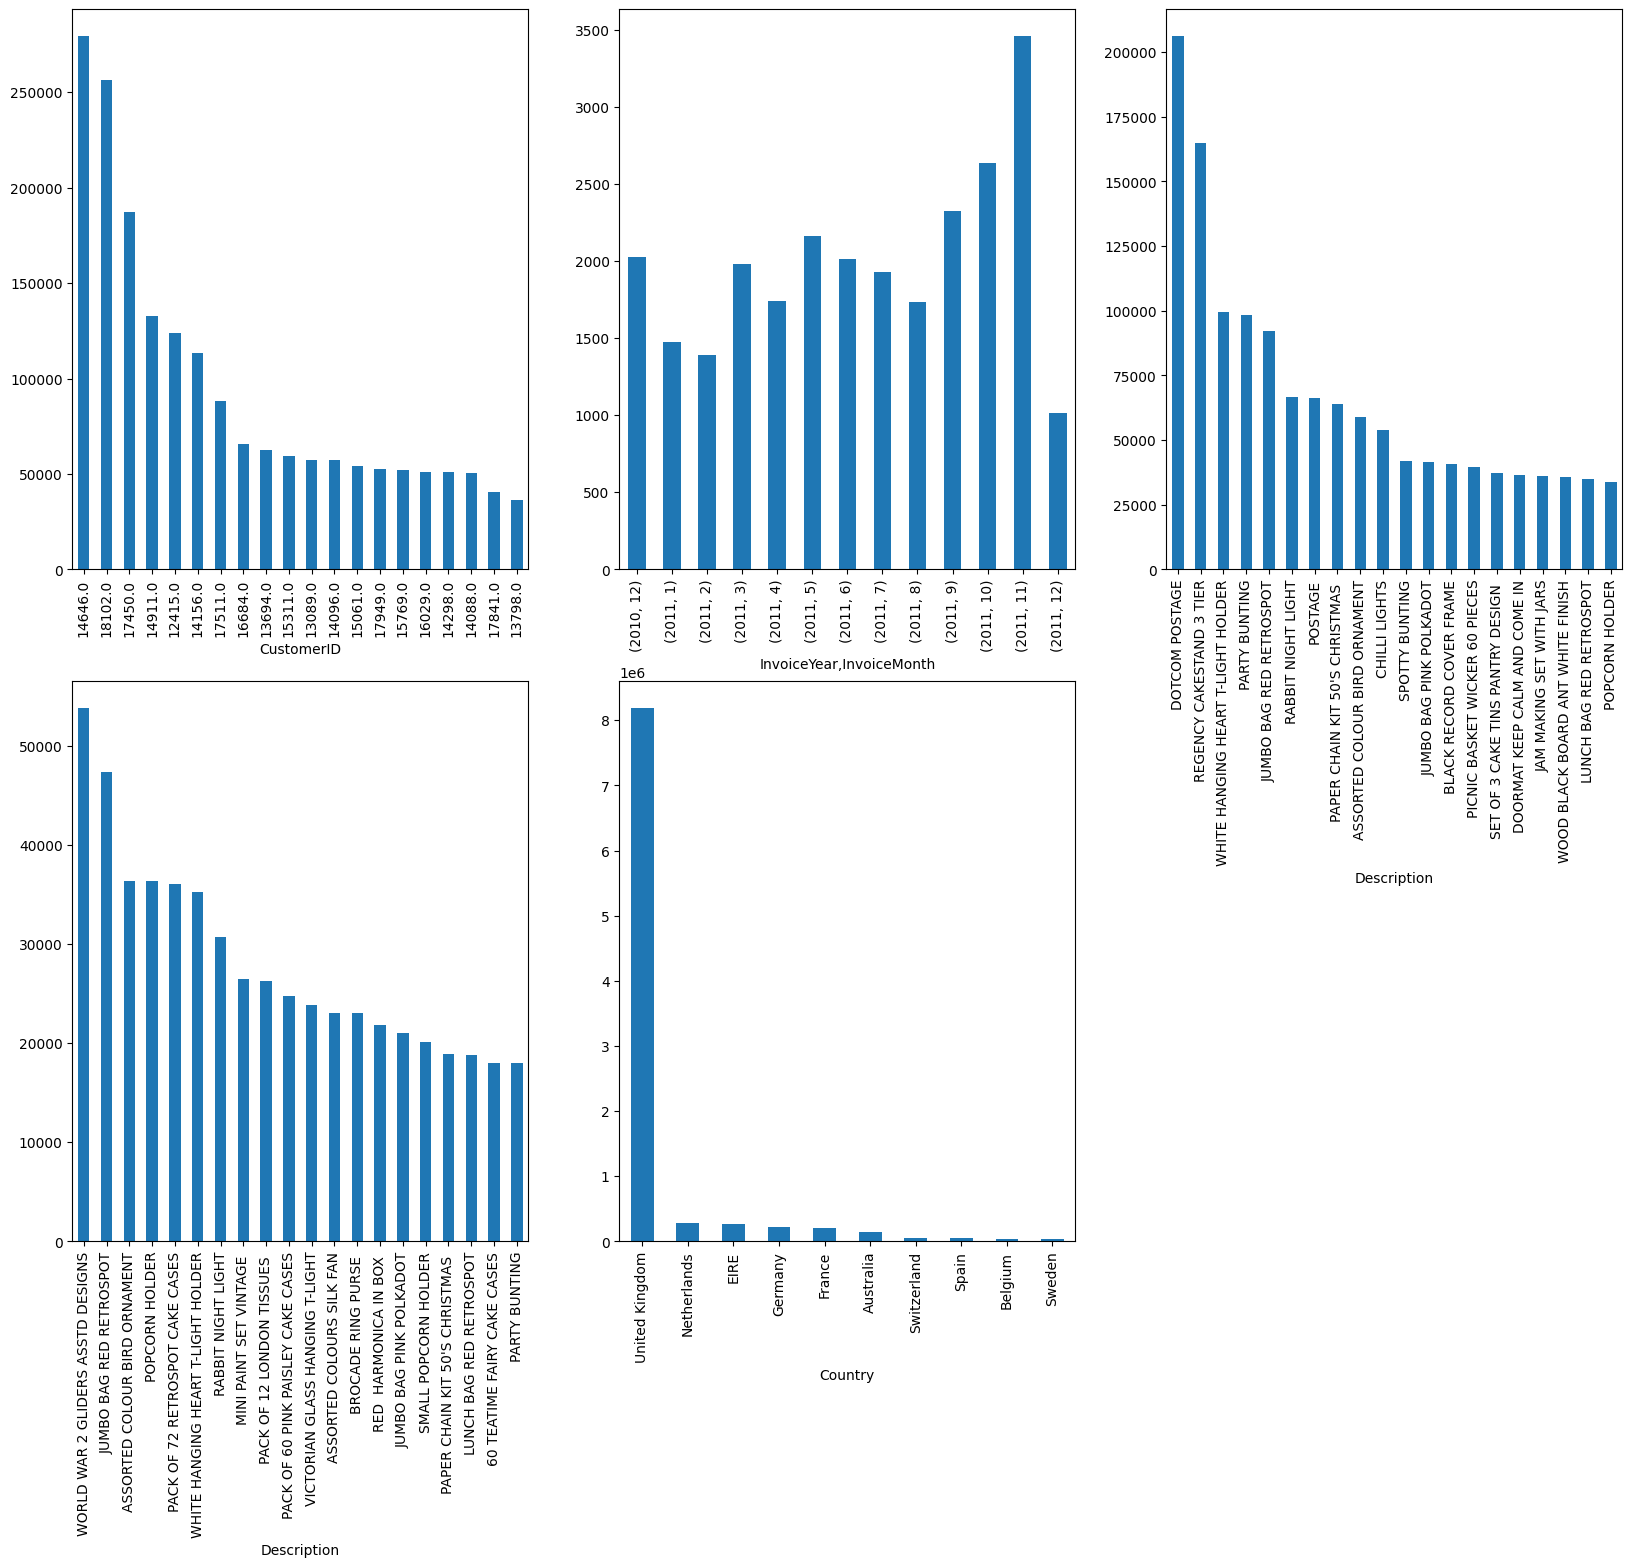

In [ ]:
# 查看产品销量排行
plt.figure(figsize=(20,16))
# 查看每名会员的总消费金额
plt.subplot(231)
customers_amounts = dataset.groupby('CustomerID')['TotalAmount'].agg(np.sum).sort_values(ascending=False)
customers_amounts.head(20).plot.bar()
# 购买月份分布
plt.subplot(232)
gp_month = dataset.sort_values('InvoiceDate').groupby(['InvoiceYear', 'InvoiceMonth'])
gp_month_invoices = gp_month['InvoiceNo'].unique().agg(np.size)
gp_month_invoices.plot.bar()
# 购买金额最多的商品
plt.subplot(233)
gp_stockcode_frq_amount = gp_stockcode['TotalAmount'].agg(np.sum).sort_values(ascending=False)
gp_stockcode_frq_amount.head(20).plot.bar()
# 购买数量最多的商品
plt.subplot(234)
gp_stockcode = dataset.groupby('Description')
gp_stockcode_frq_quantitiy = gp_stockcode['Quantity'].agg(np.sum).sort_values(ascending=False)
gp_stockcode_frq_quantitiy.head(20).plot.bar()
# 购买地区分布
plt.subplot(235)
gp_country = dataset.groupby('Country')
gp_country['TotalAmount'].agg(np.sum).sort_values(ascending=False).head(10).plot.bar()
plt.show()

### 4.3 关联规则挖掘

#### 4.3.1 将结构化数据转化为购物篮数据

购物篮数据的形式如：[牛奶 咖啡]、[纸尿裤 啤酒]等

In [ ]:
gp_invoiceno = dataset.groupby('InvoiceNo')
transactions = []
for name,group in gp_invoiceno:
    tmp = group['Description']
    tmp = tmp.drop_duplicates()
    transactions.append(list(group['Description'].map(str)))
transactions[:5]

[['WHITE HANGING HEART T-LIGHT HOLDER',
  'WHITE METAL LANTERN',
  'CREAM CUPID HEARTS COAT HANGER',
  'KNITTED UNION FLAG HOT WATER BOTTLE',
  'RED WOOLLY HOTTIE WHITE HEART.',
  'SET 7 BABUSHKA NESTING BOXES',
  'GLASS STAR FROSTED T-LIGHT HOLDER'],
 ['HAND WARMER UNION JACK', 'HAND WARMER RED POLKA DOT'],
 ['ASSORTED COLOUR BIRD ORNAMENT',
  "POPPY'S PLAYHOUSE BEDROOM ",
  "POPPY'S PLAYHOUSE KITCHEN",
  'FELTCRAFT PRINCESS CHARLOTTE DOLL',
  'IVORY KNITTED MUG COSY ',
  'BOX OF 6 ASSORTED COLOUR TEASPOONS',
  'BOX OF VINTAGE JIGSAW BLOCKS ',
  'BOX OF VINTAGE ALPHABET BLOCKS',
  'HOME BUILDING BLOCK WORD',
  'LOVE BUILDING BLOCK WORD',
  'RECIPE BOX WITH METAL HEART',
  'DOORMAT NEW ENGLAND'],
 ['JAM MAKING SET WITH JARS',
  'RED COAT RACK PARIS FASHION',
  'YELLOW COAT RACK PARIS FASHION',
  'BLUE COAT RACK PARIS FASHION'],
 ['BATH BUILDING BLOCK WORD']]

#### 4.3.2 建立 Apriori 关联规则模型

利用apyori工具包建立Apriori关联规则模型，最小支持度设为0.02，最小置信度为0.2，最小提升度为3.

In [ ]:
from apyori import apriori
rules = apriori(transactions, min_support = 0.02, min_confidence = 0.2, min_lift = 3)
results = list(rules)
len(results)

32

In [ ]:
# pip install apyori -i https://pypi.tuna.tsinghua.edu.cn/simple

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for apyori: filename=apyori-1.1.2-py3-none-any.whl size=6016 sha256=4c89309738b245bb5ebf08f8ee9d69fe44cfee244cccf4773e222214deb5fae9
  Stored in directory: c:\users\yohoten\appdata\local\pip\cache\wheels\4d\87\0d\a7b7e2d3ef8a0af17bebf186145b5c3a26a041648a8e84ca06
Successfully built apyori
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


上面代码共挖掘出了32条满足条件的关联规则。

In [ ]:
results[1]

RelationRecord(items=frozenset({'CHARLOTTE BAG PINK POLKADOT', 'RED RETROSPOT CHARLOTTE BAG'}), support=0.020308880308880308, ordered_statistics=[OrderedStatistic(items_base=frozenset({'CHARLOTTE BAG PINK POLKADOT'}), items_add=frozenset({'RED RETROSPOT CHARLOTTE BAG'}), confidence=0.6921052631578947, lift=17.0719298245614), OrderedStatistic(items_base=frozenset({'RED RETROSPOT CHARLOTTE BAG'}), items_add=frozenset({'CHARLOTTE BAG PINK POLKADOT'}), confidence=0.5009523809523809, lift=17.0719298245614)])

#### 4.3.3 查看关联规则

按提升度排序，查看前10条关联规则。

In [ ]:
my_cols = ['GeneralRules', 'LeftRules', 'RightRules', 'Support', 'Confidence', 'Lift']
final_results = pd.DataFrame(np.random.randint(low=0, high=1, size=(len(results), 6)), columns=my_cols)
index = 0
for g, s, i in results:
    final_results.iloc[index] = [' _&&_ '.join(list(g)), ' _&&_ '.join(list(i[0][0])), ' _&&_ '.join(list(i[0][1])), s, i[0][2], i[0][3]]
    index = index+1
final_results = final_results.sort_values('Lift', ascending=0)
final_results.head(10)

C:\Users\yohoten\AppData\Local\Temp\ipykernel_68432\2381772895.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'ALARM CLOCK BAKELIKE GREEN _&&_ ALARM CLOCK BAKELIKE RED ' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  final_results.iloc[index] = [' _&&_ '.join(list(g)), ' _&&_ '.join(list(i[0][0])), ' _&&_ '.join(list(i[0][1])), s, i[0][2], i[0][3]]
C:\Users\yohoten\AppData\Local\Temp\ipykernel_68432\2381772895.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'ALARM CLOCK BAKELIKE GREEN' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  final_results.iloc[index] = [' _&&_ '.join(list(g)), ' _&&_ '.join(list(i[0][0])), ' _&&_ '.join(list(i[0][1])), s, i[0][2], i[0][3]]
C:\Users\yohoten\AppData\Local\Temp\ipykernel_68432\2381772895.py:5: Fu

,GeneralRules,LeftRules,RightRules,Support,Confidence,Lift
31,ROSES REGENCY TEACUP AND SAUCER _&&_ GREEN RE...,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER _&&_ ROSES REGE...,0.021197,0.519395,21.909313
3,GARDENERS KNEELING PAD CUP OF TEA _&&_ GARDEN...,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,0.021197,0.717647,20.115865
4,GREEN REGENCY TEACUP AND SAUCER _&&_ PINK REGE...,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.024865,0.609272,19.700540
2,SPACEBOY LUNCH BOX _&&_ DOLLY GIRL LUNCH BOX,DOLLY GIRL LUNCH BOX,SPACEBOY LUNCH BOX,0.020772,0.625581,17.844227
28,PINK REGENCY TEACUP AND SAUCER _&&_ ROSES REGE...,PINK REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.023707,0.766542,17.726280
6,GREEN REGENCY TEACUP AND SAUCER _&&_ ROSES REG...,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.030270,0.741722,17.152318
1,CHARLOTTE BAG PINK POLKADOT _&&_ RED RETROSPOT...,CHARLOTTE BAG PINK POLKADOT,RED RETROSPOT CHARLOTTE BAG,0.020309,0.692105,17.071930
0,ALARM CLOCK BAKELIKE GREEN _&&_ ALARM CLOCK BA...,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.024942,0.645355,15.462244
27,PAPER CHAIN KIT VINTAGE CHRISTMAS _&&_ PAPER C...,PAPER CHAIN KIT 50'S CHRISTMAS,PAPER CHAIN KIT VINTAGE CHRISTMAS,0.021429,0.474359,14.766704
30,WOODEN PICTURE FRAME WHITE FINISH _&&_ WOODEN ...,WOODEN FRAME ANTIQUE WHITE,WOODEN PICTURE FRAME WHITE FINISH,0.021042,0.552178,12.791966


本试验中基于apriori算法，设置最小支持度0.02，最小置信度0.2，最小提升度3，挖掘得到关联规则32条。关联规则的数据集为”购物篮”形式，每个样本代表单次购买所包含的商品名称，但是不包含购买数量信息。因此关联规则对于数据信息有一定损失。


## 5. 小结

本实验通过Apriori算法实现了线上商品交易数据之间的关联规则的挖掘。通过本实验需要重点掌握关联规则挖掘原理以及Apriori算法模型的构建方法，结合各类商品交易场景，展现商品推荐的应用。
